In [2]:
#Importing data and selecting a specific parking area

import pandas as pd
import matplotlib.pyplot as plt

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('../data/Turkuparkkihub_parkings_anon.csv', delimiter=';')

# Convert 'time_start' and 'time_end' columns to datetime objects with specified format
df['time_start'] = pd.to_datetime(df['time_start'], format='%d/%m/%Y %H.%M')
df['time_end'] = pd.to_datetime(df['time_end'], format='%d/%m/%Y %H.%M')

# Define the parking space ID you want to analyze
parking_area_id = '52c37d3d-2a28-4bde-8996-fdff25e4157d'  # Example parking space ID, replace with the actual ID you want to analyze

# Filter the DataFrame for the specific parking space ID
parking_area_df = df[df['parking_area_id'] == parking_area_id]


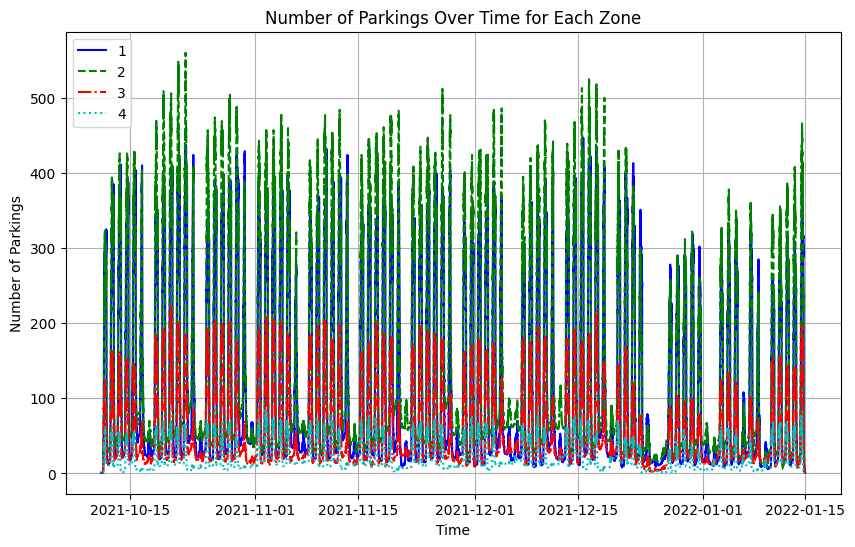

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the CSV file into a DataFrame
df = pd.read_csv('../preprocess/time_series_zones.csv')

# Convert 'Time' column to datetime type
df['Time'] = pd.to_datetime(df['Time'])

# Define line colors and styles for each zone
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k']  # Add more colors as needed
styles = ['-', '--', '-.', ':']  # Add more line styles as needed

# Group the DataFrame by 'Zone_id'
grouped_df = df.groupby('Zone_id')

# Plotting each zone's parking values over time
plt.figure(figsize=(10, 6))
for i, (zone_id, group) in enumerate(grouped_df):
    color = colors[i % len(colors)]  # Cycle through colors if there are more zones than colors
    style = styles[i % len(styles)]  # Cycle through line styles if there are more zones than styles
    plt.plot(group['Time'], group['Parkings'], label=zone_id, color=color, linestyle=style)

plt.xlabel('Time')
plt.ylabel('Number of Parkings')
plt.title('Number of Parkings Over Time for Each Zone')
plt.grid(True)
plt.legend()
plt.show()


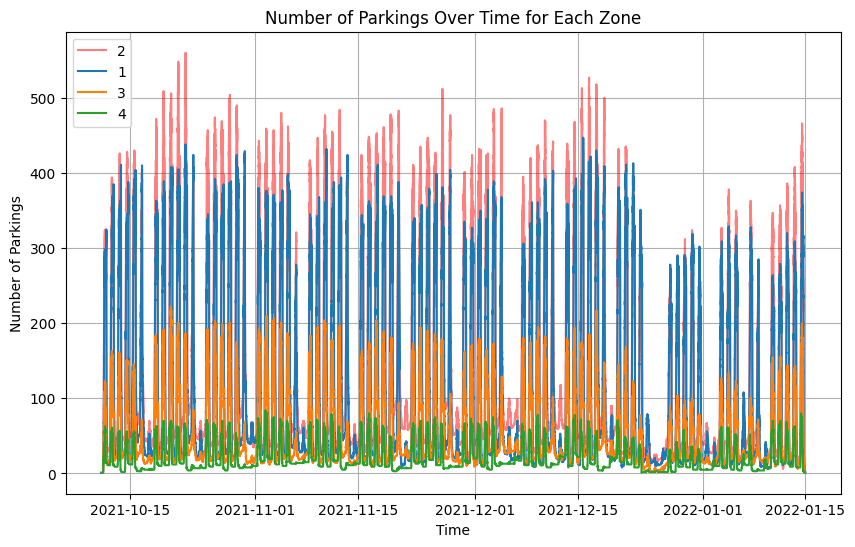

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the CSV file into a DataFrame
df = pd.read_csv('../preprocess/time_series_zones.csv')

# Convert 'Time' column to datetime type
df['Time'] = pd.to_datetime(df['Time'])

# Group the DataFrame by 'Zone_id'
grouped_df = df.groupby('Zone_id')

# Plotting Zone with ID 2 as the background
plt.figure(figsize=(10, 6))
for zone_id, group in grouped_df:
    if zone_id == 2:
        plt.plot(group['Time'], group['Parkings'], label='2', color='red', alpha=0.5)

# Plotting other zones on top of Zone ID 2
for zone_id, group in grouped_df:
    if zone_id != 2:
        plt.plot(group['Time'], group['Parkings'], label=zone_id)

plt.xlabel('Time')
plt.ylabel('Number of Parkings')
plt.title('Number of Parkings Over Time for Each Zone')
plt.grid(True)
plt.legend()
plt.show()


C:\Users\Viktor\AppData\Local\Temp\ipykernel_27716\1781939685.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  parking_area_df['weekday'] = parking_area_df['time_start'].dt.day_name()


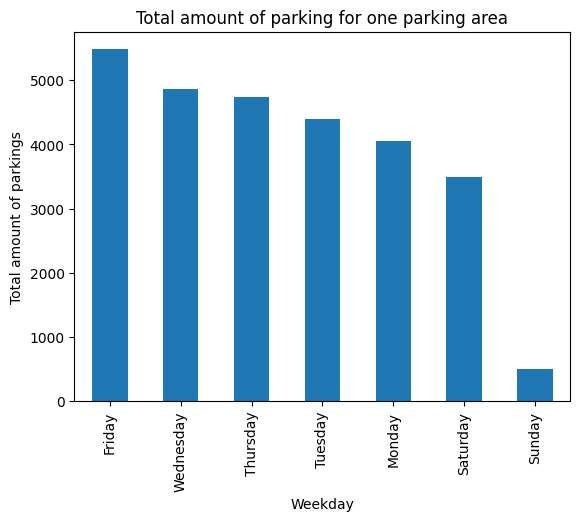

In [3]:
#Total amount per weekday

parking_area_df['weekday'] = parking_area_df['time_start'].dt.day_name()

count_df = parking_area_df['weekday'].value_counts()

count_df.plot(kind='bar', xlabel='Weekday', ylabel='Total amount of parkings', title='Total amount of parking for one parking area')
plt.show()

C:\Users\Viktor\AppData\Local\Temp\ipykernel_27716\761854588.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  parking_area_df['duration_minutes'] = (parking_area_df['time_end'] - parking_area_df['time_start']).dt.total_seconds() / 60


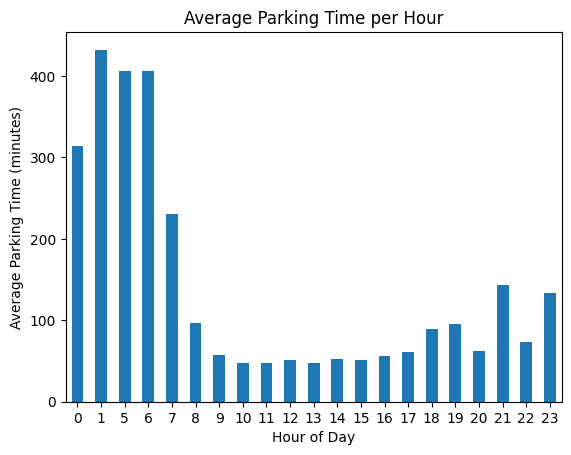

In [4]:

# Calculate duration of parking for each row
parking_area_df['duration_minutes'] = (parking_area_df['time_end'] - parking_area_df['time_start']).dt.total_seconds() / 60

# Group the DataFrame by the hour component of 'time_start', calculate average time parked for each hour
hourly_avg_parking_time = parking_area_df.groupby(parking_area_df['time_start'].dt.hour)['duration_minutes'].mean()

# Plot the average time parked for each hour
hourly_avg_parking_time.plot(kind='bar', xlabel='Hour of Day', ylabel='Average Parking Time (minutes)', title='Average Parking Time per Hour')
plt.xticks(rotation=0)
plt.show()

C:\Users\Viktor\AppData\Local\Temp\ipykernel_27716\3862974291.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  parking_count_per_hour = parking_area_df.resample('H', on='time_start').size()


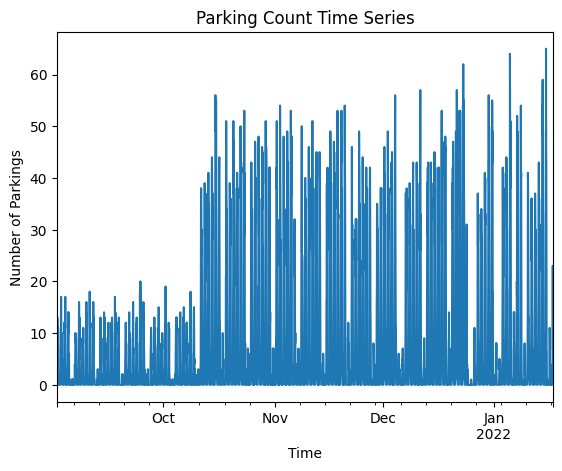

In [5]:

# Create a Series representing the count of parkings for each hour
parking_count_per_hour = parking_area_df.resample('H', on='time_start').size()

# Plot the time series of parking counts
parking_count_per_hour.plot(xlabel='Time', ylabel='Number of Parkings', title='Parking Count Time Series')
plt.show()

C:\Users\Viktor\AppData\Local\Temp\ipykernel_27716\1241386894.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_parking_counts = parking_area_df.resample('M', on='time_start').size()


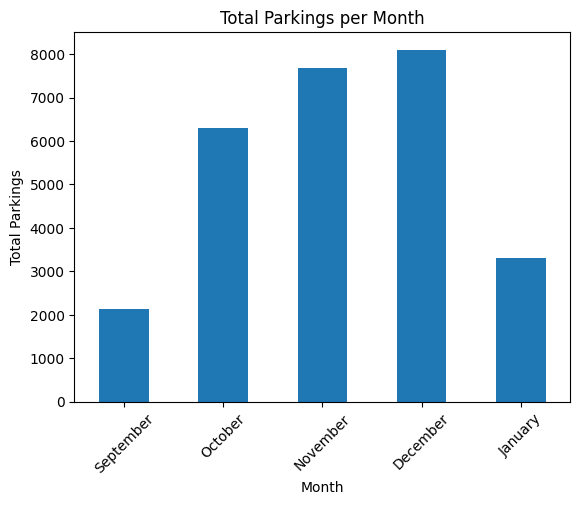

In [6]:
# Group the DataFrame by month and count the number of parkings in each month
monthly_parking_counts = parking_area_df.resample('M', on='time_start').size()

# Plot the total number of parkings per month
monthly_parking_counts.plot(kind='bar', xlabel='Month', ylabel='Total Parkings', title='Total Parkings per Month')

# Format the x-axis ticks to display month names
plt.xticks(range(len(monthly_parking_counts)), monthly_parking_counts.index.month_name(), rotation=45)

plt.show()

C:\Users\Viktor\AppData\Local\Temp\ipykernel_27716\731806462.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_parking_counts = df.resample('M', on='time_start').size()


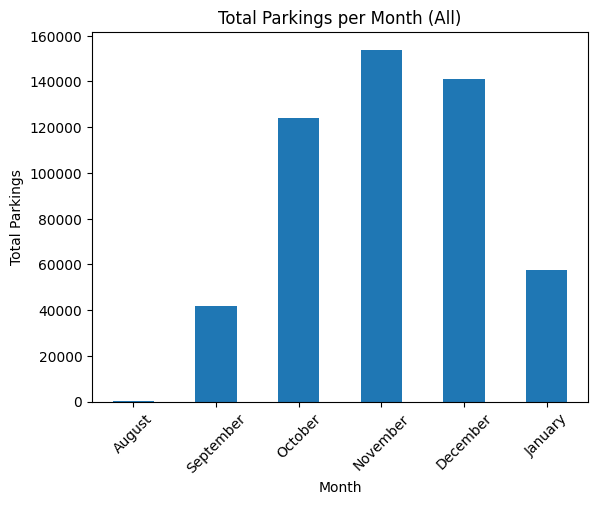

In [7]:
# All parking spaces monthly
monthly_parking_counts = df.resample('M', on='time_start').size()

# Plot the total number of parkings per month
monthly_parking_counts.plot(kind='bar', xlabel='Month', ylabel='Total Parkings', title='Total Parkings per Month (All)')

# Format the x-axis ticks to display month names
plt.xticks(range(len(monthly_parking_counts)), monthly_parking_counts.index.month_name(), rotation=45)

plt.show()

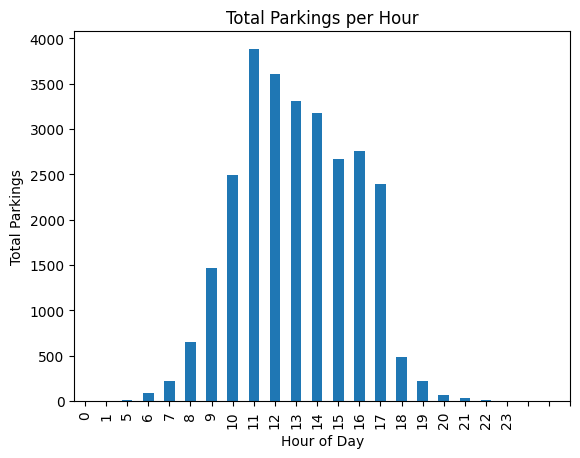

In [8]:

# Group the DataFrame by hour of the day and count the number of parkings in each hour
hourly_parking_counts = parking_area_df.groupby(parking_area_df['time_start'].dt.hour).size()

# Plot the total number of parkings per hour
hourly_parking_counts.plot(kind='bar', xlabel='Hour of Day', ylabel='Total Parkings', title='Total Parkings per Hour')

# Set the x-axis ticks to represent each hour of the day
plt.xticks(range(24))

plt.show()

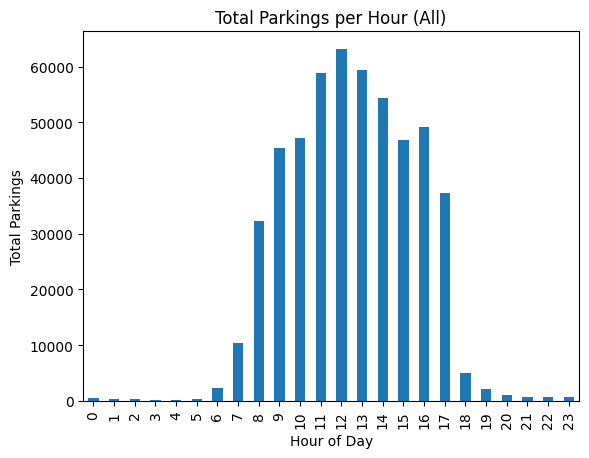

In [9]:

# Group the DataFrame by hour of the day and count the number of parkings in each hour
hourly_parking_counts = df.groupby(df['time_start'].dt.hour).size()

# Plot the total number of parkings per hour
hourly_parking_counts.plot(kind='bar', xlabel='Hour of Day', ylabel='Total Parkings', title='Total Parkings per Hour (All)')

# Set the x-axis ticks to represent each hour of the day
plt.xticks(range(24))

plt.show()

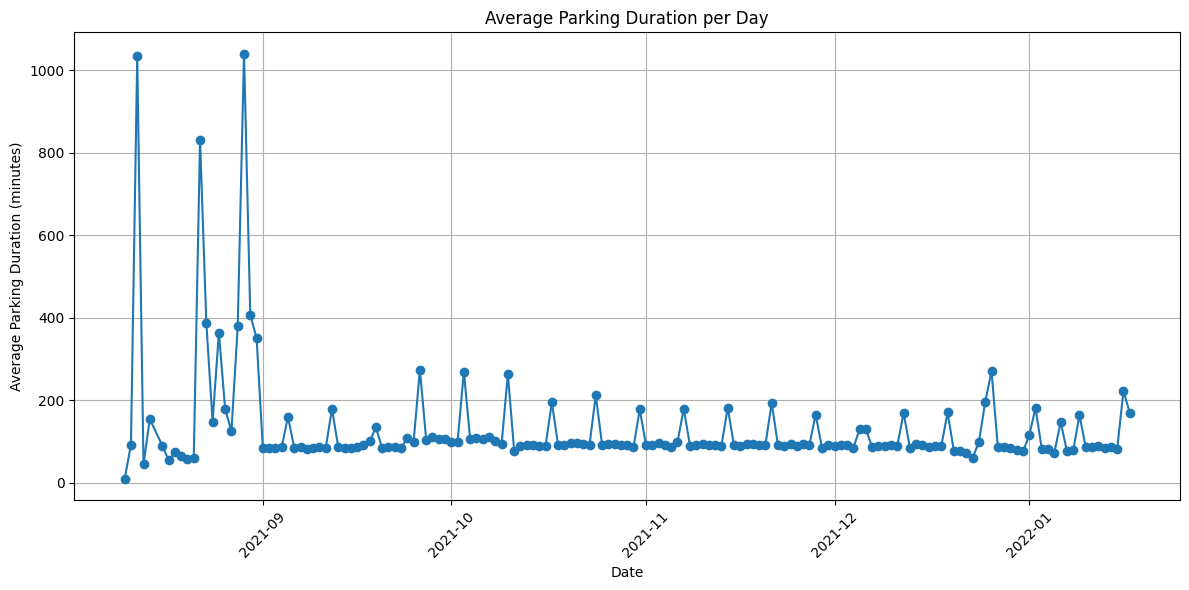

In [10]:

# Calculate the parking duration for each parking entry in minutes
df['parking_duration_minutes'] = (df['time_end'] - df['time_start']).dt.total_seconds() / 60  # Convert seconds to minutes

# Filter out entries where the parking duration is negative or excessively long (e.g., > 24 hours)
max_parking_duration_minutes = 24 * 60  # Maximum duration allowed: 24 hours
df = df[(df['parking_duration_minutes'] >= 0) & (df['parking_duration_minutes'] <= max_parking_duration_minutes)]

# Group by date and calculate the average parking duration for each day
daily_average_duration = df.groupby(df['time_start'].dt.date)['parking_duration_minutes'].mean()

# Plot the line representing the average parking duration for each day
plt.figure(figsize=(12, 6))
daily_average_duration.plot(kind='line', marker='o', linestyle='-')
plt.title('Average Parking Duration per Day')
plt.xlabel('Date')
plt.ylabel('Average Parking Duration (minutes)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

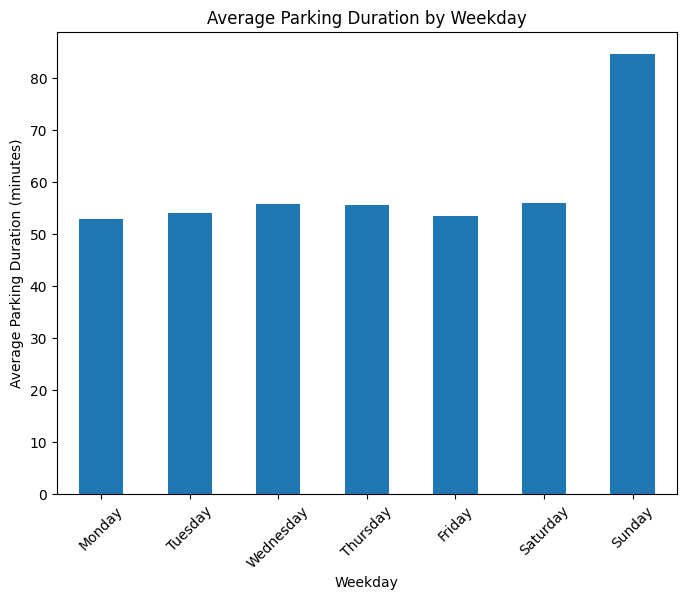

In [11]:
# Calculate the parking duration for each parking entry in minutes
df['parking_duration_minutes'] = (parking_area_df['time_end'] - parking_area_df['time_start']).dt.total_seconds() / 60  # Convert seconds to minutes

# Filter out entries where the parking duration is negative or excessively long (e.g., > 24 hours)
max_parking_duration_minutes = 24 * 60  # Maximum duration allowed: 24 hours
df = df[(df['parking_duration_minutes'] >= 0) & (df['parking_duration_minutes'] <= max_parking_duration_minutes)]

# Group by weekday and calculate the average parking duration for each weekday
weekday_average_duration = df.groupby(df['time_start'].dt.weekday)['parking_duration_minutes'].mean()

# Plot the average parking duration for each weekday
plt.figure(figsize=(8, 6))
weekday_average_duration.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_average_duration.plot(kind='bar', xlabel='Weekday', ylabel='Average Parking Duration (minutes)', title='Average Parking Duration by Weekday')
plt.xticks(rotation=45)
plt.show()

In [12]:

# Get the parking area with the most entries in the data using mode()
print(df.parking_area_id.mode())
print(df[df['parking_area_id'] == '52c37d3d-2a28-4bde-8996-fdff25e4157d'])

0    52c37d3d-2a28-4bde-8996-fdff25e4157d
Name: parking_area_id, dtype: object
              created_at       modified_at  \
25      01/09/2021 10.49  01/09/2021 11.44   
124      01/09/2021 9.06   01/09/2021 9.16   
142      01/09/2021 8.43  01/09/2021 17.12   
144     01/09/2021 15.02  01/09/2021 15.30   
196     01/09/2021 10.50  01/09/2021 11.39   
...                  ...               ...   
518469  17/01/2022 10.06  17/01/2022 10.06   
518470  17/01/2022 10.06  17/01/2022 10.06   
518490  17/01/2022 10.08  17/01/2022 10.08   
518514  17/01/2022 10.11  17/01/2022 10.11   
518535  17/01/2022 10.12  17/01/2022 10.12   

                                          id  \
25      b53859c5-ff4a-4238-ad7d-2feac23470ad   
124     9e7b92c0-bffd-41f0-8e17-64560039106e   
142     7d5741c7-9583-4369-8870-dd8ce6cbe26d   
144     e0fda29d-0753-4843-8c0d-c599f1dd0c54   
196     23547595-aae8-431c-9f70-984086f0b443   
...                                      ...   
518469  cc75e335-f729-4060-b85d-